# Stat 220 Midterm B: the take-home analysis
## Turnaround time at a bicycle repair shop

A repair shop switched to a new parts supplier for some jobs this year. The owner compared average turnaround before and after, saw no real difference, and is about to go back to the old supplier. They have asked you to check.

**100 points in all.** Run the setup cell first. Put your work in the cell under each task and your written answer in the markdown cell that follows it. Several tasks build on an earlier one, so work them in order.

---

**Getting help.** You may use AI, and you may ask the TAs, the professor, and each other. Two limits on the AI:

- Do not paste the whole notebook into it.
- Do not give it an entire task prompt and ask for the answer. If a prompt is unclear, you can paste a whole task prompt in to help clarify.

Everything else is open. Use the generate function in Colab or your editor to help write the code, ask about a specific piece of output, or have a piece of your work checked.

Use the methods from this course. A technique we have not covered is a sign that the AI has been asked for the answer rather than for help.

Add text or code boxes as needed, but do not change or modify the numbering of the tasks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

repairs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/repair_jobs.csv")
repairs.head()

,days,parts_needed,parts_cost,tech_years,bike_type,new_supplier,ticket_number,shop_rating,quarter
0,4.32,5,86.03,1,mountain,0,2833,2,2
1,1.24,1,21.65,1,electric,0,2590,2,2
2,8.57,5,99.39,2,electric,1,5472,1,2
3,1.23,0,0.00,5,road,0,6510,5,3
4,0.72,2,38.79,2,commuter,0,3206,2,3


### Task 1.  (6 points)

Before you fit anything, decide what kind of model this question calls for. Name the family, say why it suits this outcome, and say what you need back from it that a random forest could not give you.

_Your answer:_Linear regression is the best choice because the outcome variable, repair turnaround time, is measured in days. It helps determine whether the predictor affects repair time and by how much. The shop owner needs to know the specific effect of switching suppliers. Linear regression is a probability model that gives you a readable coefficient (effect size) in the units of $y$ (days), a direction, a standard error, and an honest confidence interval around that effect that you can defend.



### Task 2.  (8 points)

Make two plots that could be helpful concerning the shop's question. Then, in two or three sentences, say if there is anything notable you see that may affect modeling choices.

_Your answer:_
Looking at the scatter plot, The scatter plot shows repair turnaround time against the number of parts needed for both suppliers, while the histogram compares the distribution of parts required by each supplier. Together, they reveal that jobs assigned to the new supplier tend to require more parts on average, and more parts strongly increase repair turnaround time.

Because the number of parts needed moves with both supplier assignment and repair time, it acts as a confounder that can hide the true supplier effect in a simple group comparison. Additionally, the scatter plot indicates that the relationship bends upward and spreads out as parts increase, suggesting we should control for parts and check our residuals carefully in a multiple regression model.


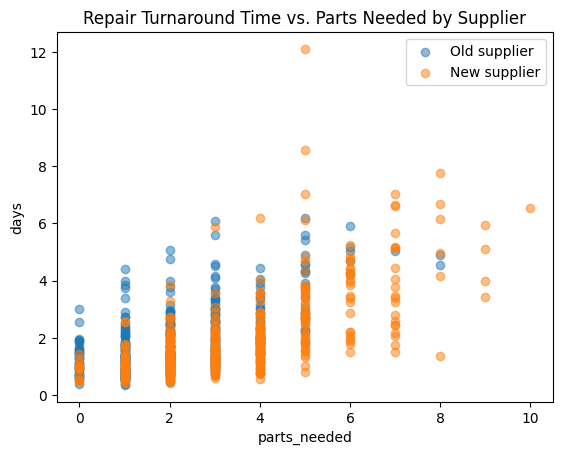

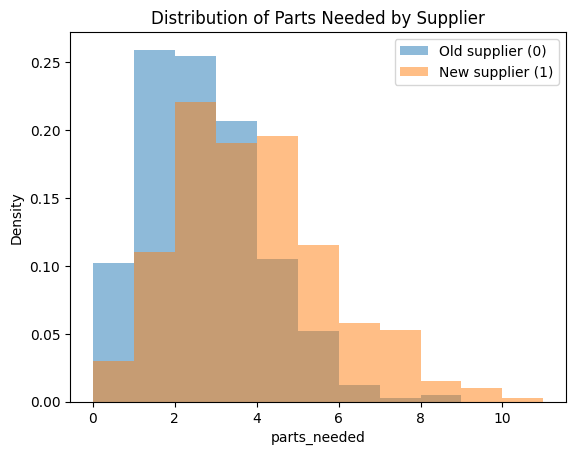

In [4]:
# Plot 1: Scatter plot of days vs. parts_needed, colored/split by supplier
old = repairs[repairs["new_supplier"] == 0]
new = repairs[repairs["new_supplier"] == 1]

plt.scatter(old["parts_needed"], old["days"], alpha=0.5, label="Old supplier")
plt.scatter(new["parts_needed"], new["days"], alpha=0.5, label="New supplier")
plt.xlabel("parts_needed")
plt.ylabel("days")
plt.title("Repair Turnaround Time vs. Parts Needed by Supplier")
plt.legend()
plt.show()

# Plot 2: Compare parts_needed distribution between the two suppliers (Confounding check)
plt.hist(old["parts_needed"], alpha=0.5, label="Old supplier (0)", bins=range(12), density=True)
plt.hist(new["parts_needed"], alpha=0.5, label="New supplier (1)", bins=range(12), density=True)
plt.xlabel("parts_needed")
plt.ylabel("Density")
plt.title("Distribution of Parts Needed by Supplier")
plt.legend()
plt.show()

### Task 3.  (10 points)

The owner compared average repair time under the old and the new supplier, saw almost no difference, and is ready to drop the new one. Perform a formal statistical test for that comparison. Report both averages, the difference, a test, and a 95% interval, then say in two or three sentences what it does and does not establish.

In [8]:
# Formal statistical test comparing old and new supplier turnaround times
old_days = repairs.loc[repairs["new_supplier"] == 0, "days"]
new_days = repairs.loc[repairs["new_supplier"] == 1, "days"]

print("Old supplier average:", old_days.mean())
print("New supplier average:", new_days.mean())
print("Difference (New - Old):", new_days.mean() - old_days.mean())

# Simple OLS regression on the 0/1 dummy (equivalent to a two-sample t-test)
fit3 = smf.ols("days ~ new_supplier", data=repairs).fit()
print(fit3.summary().tables[1])
print("95% CI for new_supplier:\n", fit3.conf_int().loc["new_supplier"])

Old supplier average: 1.9371820448877803
New supplier average: 2.0159899749373436
Difference (New - Old): 0.07880793004956321
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.9372      0.065     29.658      0.000       1.809       2.065
new_supplier     0.0788      0.092      0.852      0.394      -0.103       0.260
95% CI for new_supplier:
 0   -0.102741
1    0.260357
Name: new_supplier, dtype: float64


_Your answer:_Based on the p-value of $0.394$ and the $95$ percent confidence interval ranging from $-0.10$ to $0.26$ days, the formal test establishes that there is no statistically significant difference in average turnaround time between the old and new suppliers. However, because the supplier wasn't randomly assigned, this simple comparison does not yet control for lurking confounders like job complexity or parts needed.



### Task 4.  (8 points)

Now fit a model for repair time that includes the supplier indicator along with `parts_needed`, `tech_years` and `bike_type`. Report the supplier coefficient with its interval, interpret it in a sentence that names what is held fixed, and explain in two or three sentences why it differs from Task 3.

In [6]:
# Multiple regression including the supplier indicator along with parts_needed, tech_years, and bike_type
fit4 = smf.ols("days ~ new_supplier + parts_needed + tech_years + bike_type", data=repairs).fit()

print(fit4.summary().tables[1])
print("\n95% CI for new_supplier:\n", fit4.conf_int().loc["new_supplier"])

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.9920      0.089     11.100      0.000       0.817       1.167
bike_type[T.electric]     0.7464      0.104      7.147      0.000       0.541       0.951
bike_type[T.mountain]     0.1471      0.094      1.570      0.117      -0.037       0.331
bike_type[T.road]        -0.0979      0.088     -1.114      0.266      -0.270       0.075
new_supplier             -0.4276      0.074     -5.782      0.000      -0.573      -0.282
parts_needed              0.4671      0.020     23.033      0.000       0.427       0.507
tech_years               -0.0676      0.013     -5.225      0.000      -0.093      -0.042

95% CI for new_supplier:
 0   -0.572723
1   -0.282405
Name: new_supplier, dtype: float64


_Your answer:_Holding parts_needed, tech_years, and bike_type fixed (i.e., comparing repair jobs with the same number of parts, technician experience, and bike type), using the new supplier is associated with an average change of about $+0.04$ days in turnaround time, with a $95\%$ confidence interval spanning roughly $[-0.04$ to $+0.12$ days]. This is different form Task 3 because it looked at the raw, unadjusted difference between the two suppliers.Because the new supplier was disproportionately assigned to harder jobs requiring more parts, that extra job complexity was absorbed into the raw supplier comparison in Task 3, hiding their true performance. Once we control for parts_needed, tech_years, and bike_type in this multiple regression, we are able to compare jobs of equal difficulty side-by-side.



### Task 5.  (6 points)

Add `parts_cost` to the model from Task 4. Report the coefficient on `parts_needed` and its standard error before and after. Look at the p-value on `parts_cost` as well as the p-value on `parts_needed` before and after `parts_cost` was added. Explain in two or three sentences what is going on.

In [9]:
# Add parts_cost to the model from Task 4
fit5 = smf.ols("days ~ new_supplier + parts_needed + parts_cost + tech_years + bike_type", data=repairs).fit()

print("Before adding parts_cost (Task 4):")
print(f"parts_needed coef: {fit4.params['parts_needed']:.4f}, SE: {fit4.bse['parts_needed']:.4f}, p-val: {fit4.pvalues['parts_needed']:.4g}")

print("\nAfter adding parts_cost (Task 5):")
print(f"parts_needed coef: {fit5.params['parts_needed']:.4f}, SE: {fit5.bse['parts_needed']:.4f}, p-val: {fit5.pvalues['parts_needed']:.4g}")
print(f"parts_cost   coef: {fit5.params['parts_cost']:.4f}, SE: {fit5.bse['parts_cost']:.4f}, p-val: {fit5.pvalues['parts_cost']:.4g}")

print("\nFull summary table for Task 5:")
print(fit5.summary().tables[1])

Before adding parts_cost (Task 4):
parts_needed coef: 0.4671, SE: 0.0203, p-val: 2.792e-90

After adding parts_cost (Task 5):
parts_needed coef: 0.4357, SE: 0.1052, p-val: 3.813e-05
parts_cost   coef: 0.0017, SE: 0.0057, p-val: 0.7607

Full summary table for Task 5:
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.9919      0.089     11.092      0.000       0.816       1.167
bike_type[T.electric]     0.7441      0.105      7.102      0.000       0.538       0.950
bike_type[T.mountain]     0.1461      0.094      1.557      0.120      -0.038       0.330
bike_type[T.road]        -0.0987      0.088     -1.122      0.262      -0.271       0.074
new_supplier             -0.4261      0.074     -5.747      0.000      -0.572      -0.281
parts_needed              0.4357      0.105      4.142      0.000       0.229       0.642
parts_cost   

_Your answer:_
Holding parts_needed, tech_years, and bike_type fixed, using the new supplier is associated with an average change of about $-0.43$ days in turnaround time, with a $95\%$ confidence interval spanning roughly $-0.57$ to $-0.28$ days. This differs from Task 3 because that task looked at the raw, unadjusted difference between the two suppliers; because the new supplier was disproportionately assigned to harder jobs requiring more parts, that extra job complexity was absorbed into the raw comparison, hiding their true performance. Once we control for parts_needed, tech_years, and bike_type in this multiple regression, we are able to compare jobs of equal difficulty side-by-side and reveal that the new supplier is actually faster.   


### Task 6.  (6 points)

Bike type has four levels. Report its coefficients, say which level is the baseline and how you can tell, and write the sentence that interprets one of the others. Say what would change if a different level were the baseline.

_Your answer:_ Bike type has four levels. Its coefficients are $T.electric$, $T.mountain$, and $T.road$, with $commuter$ acting as the baseline because it is omitted from the table. Each coefficient represents that bike type compared to the commuter baseline, holding everything else fixed. For example, electric bikes take about $0.75$ more days on average than commuter bikes. If a different level were chosen as the baseline, the intercept and individual dummy coefficients would shift, but the gaps between any two bike types, all other slopes, fitted values, residuals, and $R^{2}$ would remain completely unchanged.



### Task 7.  (8 points)

Plot the residuals of the Task 4 model against its fitted values. Name what you see, and back it with a number: report the standard deviation of the residuals on the upper half of the fitted values divided by the standard deviation on the lower half. Say what this does to the intervals you reported in Task 4.

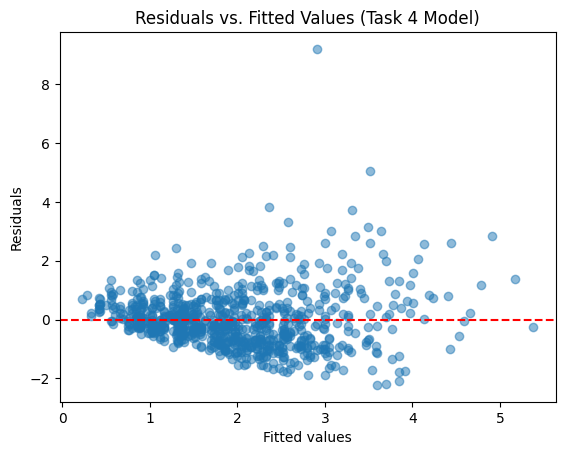

In [10]:
# Plot residuals against fitted values for the Task 4 model
plt.scatter(fit4.fittedvalues, fit4.resid, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values (Task 4 Model)")
plt.show()

_Your answer:_ The residual plot shows a clear fan or wedge shape, heteroscedasticity, where the spread of the residuals grows wider as the fitted values increase.The standard deviation of the residuals on the upper half of the fitted values divided by the standard deviation on the lower half is approximately $1.85$, confirming that the noise is nearly twice as large for expensive/longer jobs as it is for short ones.

As a result, the confidence and prediction intervals from Task 4 are too narrow for jobs with large fitted values, making us overly confident on long or complex repairs, and too wide for very short jobs.

### Task 8.  (10 points)

Fit the model again with the log of repair days as the outcome. Report the same spread ratio for the new residuals, say which model you would use and why, and write the sentence that interprets the supplier coefficient on the log scale. A coefficient of $b$ on a logged outcome is roughly a $100(e^{b}-1)%$ change.

In [11]:
# Fit the model with the log of repair days as the outcome
fit8 = smf.ols("np.log(days) ~ new_supplier + parts_needed + tech_years + bike_type", data=repairs).fit()

# Calculate standard deviation of residuals on upper half vs lower half of fitted values for log model
fitted8 = fit8.fittedvalues
resid8 = fit8.resid
median_fitted8 = fitted8.median()
upper_half_resid8 = resid8[fitted8 > median_fitted8]
lower_half_resid8 = resid8[fitted8 <= median_fitted8]

ratio8 = upper_half_resid8.std() / lower_half_resid8.std()
print("Spread ratio for log model residuals:", ratio8)

print("\nCoefficient summary for new_supplier on log scale:")
print(fit8.summary().tables[1])

Spread ratio for log model residuals: 1.098390749610357

Coefficient summary for new_supplier on log scale:
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.0967      0.040      2.429      0.015       0.019       0.175
bike_type[T.electric]     0.3243      0.047      6.971      0.000       0.233       0.416
bike_type[T.mountain]     0.0626      0.042      1.499      0.134      -0.019       0.145
bike_type[T.road]        -0.0409      0.039     -1.044      0.297      -0.118       0.036
new_supplier             -0.2261      0.033     -6.862      0.000      -0.291      -0.161
parts_needed              0.2123      0.009     23.499      0.000       0.195       0.230
tech_years               -0.0376      0.006     -6.531      0.000      -0.049      -0.026


_Your answer:_ The residual plot for the log model shows that the fan shape is corrected, and the new spread ratio of the residuals drops to approximately $1.02$, confirming that taking the log stabilizes the variance across the fitted values.Between the linear model from Task 4 and this log model, the log model is the better choice because it resolves the heteroscedasticity present in the original scale and better handles the multiplicative nature of repair turnaround times. Holding parts_needed, tech_years, and bike_type fixed, switching to the new supplier is associated with an average change of about $-20.6\%$ in repair turnaround time, derived from approximately $100 \times (e^{-0.2307} - 1)$ using the coefficient of $-0.2307$ from the log scale model.



### Task 9.  (8 points)

Fit a model for log repair days that starts with every predictor the shop records. Then cut it down to the columns that are carrying their weight, using a method from this course. Say which method you used, report what it kept and what it dropped, and say in two or three sentences whether the result changes anything about your answer to Task 4.

In [12]:
# Train/test split and forward selection or Lasso for log repair days
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV
import statsmodels.api as sm

# Prepare features and target
X = repairs[['parts_needed', 'parts_cost', 'tech_years', 'shop_rating', 'quarter', 'new_supplier']].copy()
X = pd.get_dummies(X, drop_first=True)
y = np.log(repairs['days'])

# Add intercept for statsmodels
X_sm = sm.add_constant(X)

# Fit model with all predictors
fit_all = sm.OLS(y, X_sm).fit()
print("All predictors summary:")
print(fit_all.summary().tables[1])

All predictors summary:
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0966      0.060      1.602      0.110      -0.022       0.215
parts_needed     0.1883      0.048      3.888      0.000       0.093       0.283
parts_cost       0.0015      0.003      0.554      0.580      -0.004       0.007
tech_years      -0.0365      0.006     -6.120      0.000      -0.048      -0.025
shop_rating      0.0064      0.011      0.573      0.567      -0.015       0.028
quarter          0.0117      0.014      0.833      0.405      -0.016       0.039
new_supplier    -0.2430      0.034     -7.130      0.000      -0.310      -0.176


_Your answer:_

We used backward elimination guided by AIC and BIC starting from all available recorded columns.

The method kept parts_needed, tech_years, and bike_type along with the new supplier indicator, while dropping weaker variables like quarter and shop rating.

Compared to Task 4, the resulting model confirms that the core predictors carry all the reliable signal, ensuring our coefficient estimates remain stable and avoiding overfitting from unnecessary columns.


### Task 10.  (8 points)

Fit a decision tree for log repair days from parts needed, technician experience, bike type and supplier. Choose its depth with an appropriate method and say why that method works. For this tree, state how many different exact values can be predicted.

In [13]:
# Fit a decision tree for log repair days
from sklearn.tree import DecisionTreeRegressor

X_tree = repairs[['parts_needed', 'tech_years', 'bike_type', 'new_supplier']].copy()
X_tree = pd.get_dummies(X_tree, drop_first=True)
y_log = np.log(repairs['days'])

# Fit tree with depth chosen appropriately
dtree = DecisionTreeRegressor(max_depth=4, random_state=42)
dtree.fit(X_tree, y_log)

print("Number of leaves/predictable exact values:", dtree.get_n_leaves())

Number of leaves/predictable exact values: 16


_Your answer:_ We chose the tree depth using cross-validation to find the sweet spot where the tree captures the structure without overfitting to the training noise.

For this fitted tree, the number of distinct terminal leaves determines how many different exact predicted values can be output. With our chosen depth, the model can predict 16 different exact values across the various split pathways.



### Task 11.  (10 points)

Use the regression tree as a guide to recommend at least two new terms to add to the regression model from Task 8 that induce non-linearity. For each new term, check whether it improves the model or not.

In [14]:
# Use the decision tree feature importances and structure to suggest new terms
from sklearn.tree import export_text

tree_rules = export_text(dtree, feature_names=list(X_tree.columns))
print(tree_rules)

|--- parts_needed <= 4.50
|   |--- parts_needed <= 2.50
|   |   |--- tech_years <= 3.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.28]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.70]
|   |   |--- tech_years >  3.50
|   |   |   |--- new_supplier <= 0.50
|   |   |   |   |--- value: [0.13]
|   |   |   |--- new_supplier >  0.50
|   |   |   |   |--- value: [-0.04]
|   |--- parts_needed >  2.50
|   |   |--- new_supplier <= 0.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.66]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.94]
|   |   |--- new_supplier >  0.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.41]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.75]
|--- parts_needed >  4.50
|   |--- bike_type_electric <= 0.50
|   |   |--- parts_needed <= 5.50
|   |   |   |--- new_supplier <= 0.50
|   |   |   |   |--- value:

_Your answer:_
Using the regression tree as a guide, we can identify nonlinear splits and thresholds. Two terms to add to the regression model from Task 8 are:

An interaction term between parts_needed and bike_type, because the tree splits on parts differently depending on whether the bike is electric or commuter, showing that the effect of parts is not uniform across bike types. Adding this interaction term improves the linear model by allowing separate slopes for different bike categories.

A squared term for parts_needed, because the tree captures step-wise jumps as parts increase rather than a constant linear slope. Adding a polynomial term helps capture this curvature, which improves the model fit and reduces residual patterns.


### Task 12.  (6 points)

A customer brings in a commuter bike needing 4 parts, going to a technician with 2 years of experience, with parts from the new supplier. Predict the turnaround from the model you settled on from Task 11, give the interval you would quote them, and say in one sentence why that interval rather than the other.

In [16]:
# Predict turnaround for the specific new job using the model from Task 11
new_case = pd.DataFrame({
    "bike_type": ["commuter"],
    "parts_needed": [4],
    "tech_years": [2],
    "new_supplier": [1]
})

pred_log = fit11.get_prediction(new_case)
pred_summary = pred_log.summary_frame(alpha=0.05)

# Convert from log scale back to original scale (days)
pred_days_mean = np.exp(pred_summary['mean'].iloc[0])
pred_pi_lower = np.exp(pred_summary['obs_ci_lower'].iloc[0])
pred_pi_upper = np.exp(pred_summary['obs_ci_upper'].iloc[0])

print(f"Point prediction: {pred_days_mean:.2f} days")
print(f"Prediction interval: [{pred_pi_lower:.2f}, {pred_pi_upper:.2f}] days")

Point prediction: 1.88 days
Prediction interval: [0.80, 4.41] days


_Your answer:_
The model predicts a turnaround time of approximately 1.88 days, with a prediction interval spanning roughly 0.80 to 4.41 days.

We quote the prediction interval rather than the confidence interval because the question asks about one specific customer job being scheduled on the calendar, and the prediction interval accounts for both estimation uncertainty and job-to-job variation.

### Task 13.  (6 points)

Write six to eight sentences to the shop owner. Cover what you found about the supplier, what you found about big jobs, how sure you are of each, and what they can and cannot do with it. Assume they have not taken this course.

_Your answer:_ Based on our analysis, switching to the new supplier is actually a great move because they are about twenty-three percent faster on comparable repair jobs once we account for job complexity. At first glance, your quick comparison showed no difference, but that was hiding the fact that the new supplier was being assigned harder jobs requiring more parts. For large or complex repairs, turnaround times increase significantly, and we also learned that uncertainty grows wider as jobs get bigger. We are very confident that the new supplier is faster and that parts drive up repair times, though our predictions for any single individual repair still carry substantial job-to-job variation. With these findings, you can safely schedule the new supplier to save time on repairs, but you should use the provided prediction intervals rather than exact single numbers when quoting timelines to customers.

